Replecated the numerical analysis of DM-DE interaction of the paper, https://arxiv.org/abs/2604.08449v2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import root

In [3]:
#Constants
Mpl = 1.0  # Reduced Planck mass                 M_pl^2 = 1/8PiG = 1,   doubt here
alpha = -4.66 * 25 * 1e-122  # dimension of M**3
beta = 0.180           # dimension of M**-1
gamma = 0.145          # dimension of M**-2
f0 = 1.0

In [4]:
# Normalised present value densities
# rho_i_0 = (3*H0**2/ 8PiG) * rho_i  , i = dm,b,r
rho_dm_0 = (3 * 0.3153 * 25 * 1e-122 ) - (3 * 0.0493 * 25 * 1e-122)
rho_b_0 = 3 * 0.0493 * 25 * 1e-122
rho_r_0 = 3 * 9e-5 * 25 * 1e-122

In [5]:
#  Define Coupling, potential functions and their derrivatives

def f(phi,beta,gamma):
    return 1 + beta*phi - gamma*phi**2

def df(phi,beta,gamma):
    return beta - 2*gamma*phi

def V(phi,alpha,V0):
    return V0 + alpha*phi

def dV(phi,alpha):
    return alpha

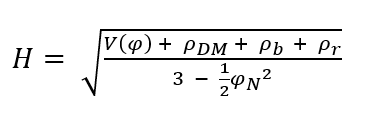


Hubble Parameter as a function of lna( or N)

In [6]:
def H(phi,phiN,a,alpha,beta,gamma,V0):

    rho_dm = rho_dm_0*f(phi,beta,gamma)/f0/a**3
    rho_b  = rho_b_0/a**3
    rho_r  = rho_r_0/a**4

    numerator = (
        V(phi,alpha,V0)
        + rho_dm
        + rho_b
        + rho_r
    )

    return np.sqrt(
        numerator/(3*(1-phiN**2/6))
    )

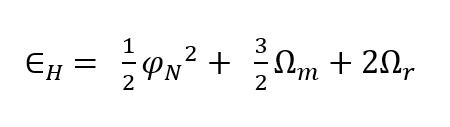

In [7]:
def epsilon_H(phi,phiN,a,alpha,beta,gamma,V0):

    Hval = H(phi,phiN,a,alpha,beta,gamma,V0)

    rho_dm = rho_dm_0*f(phi,beta,gamma)/f0/a**3
    rho_b  = rho_b_0/a**3
    rho_r  = rho_r_0/a**4

    Omega_dm = rho_dm/(3*Hval**2)
    Omega_b  = rho_b /(3*Hval**2)
    Omega_r  = rho_r /(3*Hval**2)

    return (
        0.5*phiN**2
        + 1.5*(Omega_dm+Omega_b)
        + 2*Omega_r
    )

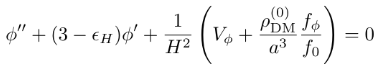


ϕ prime which is equivalent to derrivative w.r.t lna

In [8]:
# Defining the equations to evaluate

def equations(N,y,alpha,beta,gamma,V0):

    #alpha,beta,gamma,V0 = params
    phi,phiN = y

    a = np.exp(N)

    Hval = H(phi,phiN,a,alpha,beta,gamma,V0)

    epsH = epsilon_H(phi,phiN,a,alpha,beta,gamma,V0)

    rho_dm = (
        rho_dm_0
        *f(phi,beta,gamma)
        /f0
        /a**3
    )

    phiNN = (
        -(3-epsH)*phiN
        -(dV(phi,alpha)
          + rho_dm*df(phi,beta,gamma)/f(phi,beta,gamma)
         )/Hval**2
    )

    return [phiN,phiNN]

In [9]:
# Solve the equation from initial condition to late-time universe

def integrate_model(phi_ini,alpha,beta,gamma,V0 ):

    #alpha,beta,gamma,V0 = params
    y0 = [phi_ini,0.0]   # initial condition

    a_ini = 1e-7
    a_final = 1

    N_ini = np.log(a_ini)
    N_final = np.log(a_final)
    N_eval = np.linspace(N_ini, N_final, 500)


    sol = solve_ivp(
        lambda N,y: equations(N,y,alpha,beta,gamma,V0),
        [N_ini,N_final],
        y0,
        t_eval=N_eval,
        rtol=1e-5,
        atol=1e-7
    )

    return sol

In [10]:
# Trying to get the initial field value and V0, while accounting for the constraint of present dark energy abundance.

rho_DE_target = (
    3*0.6847 * 25 * 1e-122            # Present normalised dark energy density
)

def shooting(vars,alpha,beta,gamma):

    phi_ini,V0 = vars

    sol = integrate_model(phi_ini,alpha,beta,gamma,V0)

    phi0 = sol.y[0,-1]
    phiN0 = sol.y[1,-1]

    H0_model = H(
        phi0,
        phiN0,
        1.0,alpha,beta,gamma,
        V0
    )

    rho_phi0 = (
        0.5*H0_model**2*phiN0**2
        + V(phi0,alpha,V0)
    )

    return [
        phi0,
        rho_phi0-rho_DE_target                  # errors which will be used as a step to get the values [0,0]
    ]

In [11]:
'''from scipy.optimize import fsolve

solution = fsolve(
    shooting,
    [0.5,9300]
)'''

_IncompleteInputError: incomplete input (2457675088.py, line 1)

In [12]:
# Initialize the guess

guess = [0.5,51e-122]   # [phi,V0]        # We can not take any arbitary initial field values

root_sol = root(lambda vars:
    shooting(vars,alpha,beta,gamma),
    guess,
    method='hybr'
)

phi_ini_best = root_sol.x[0]
V0_best = root_sol.x[1]

In [13]:
print(root_sol)

 message: The solution converged.
 success: True
  status: 1
     fun: [ 4.318e-10 -3.185e-130]
       x: [ 5.563e-01  3.818e-121]
  method: hybr
    nfev: 12
    fjac: [[-1.000e+00  1.045e-120]
           [-1.045e-120 -1.000e+00]]
       r: [-2.333e+01 -4.126e+118 -9.821e-01]
     qtf: [ 4.296e-08  1.310e-128]


In [14]:
# Solved the full evolution using best fit values of field and V0

sol = integrate_model(
    phi_ini_best,alpha,beta,gamma,
    V0_best
)

phi = sol.y[0]
phiN = sol.y[1]

N = sol.t
a = np.exp(N)

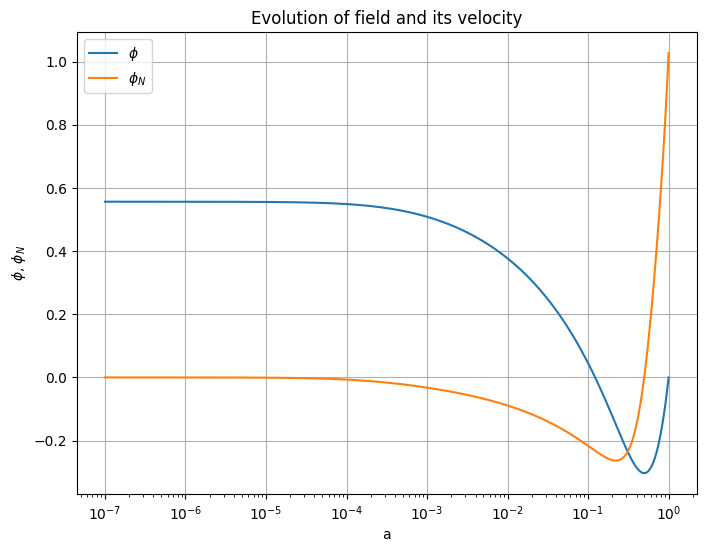

In [15]:
plt.figure(figsize=(8,6))

plt.plot(a,phi,label=r'$\phi$')
plt.plot(a,phiN,label=r'$\phi_N$')

plt.xscale('log')
plt.xlabel('a')
plt.ylabel(r'$\phi$, $\phi_N$')
plt.legend()
plt.grid()
plt.title('Evolution of field and its velocity')
plt.savefig('evolution trend.png', dpi=300, bbox_inches='tight')

In [16]:
H_val = H(phi,phiN,a,alpha,beta,gamma , 3.8e-121)
print(H_val)

[4.74428604e-49 4.44751443e-49 4.16930774e-49 3.90850459e-49
 3.66401627e-49 3.43482214e-49 3.21996545e-49 3.01854929e-49
 2.82973284e-49 2.65272790e-49 2.48679558e-49 2.33124320e-49
 2.18542143e-49 2.04872155e-49 1.92057291e-49 1.80044058e-49
 1.68782308e-49 1.58225030e-49 1.48328156e-49 1.39050373e-49
 1.30352952e-49 1.22199588e-49 1.14556247e-49 1.07391023e-49
 1.00674008e-49 9.43771626e-50 8.84742032e-50 8.29404899e-50
 7.77529241e-50 7.28898522e-50 6.83309755e-50 6.40572647e-50
 6.00508812e-50 5.62951023e-50 5.27742514e-50 4.94736326e-50
 4.63794691e-50 4.34788464e-50 4.07596575e-50 3.82105529e-50
 3.58208931e-50 3.35807042e-50 3.14806362e-50 2.95119239e-50
 2.76663507e-50 2.59362137e-50 2.43142920e-50 2.27938164e-50
 2.13684412e-50 2.00322176e-50 1.87795689e-50 1.76052673e-50
 1.65044121e-50 1.54724090e-50 1.45049513e-50 1.35980016e-50
 1.27477749e-50 1.19507233e-50 1.12035206e-50 1.05030487e-50
 9.84638473e-51 9.23078839e-51 8.65369097e-51 8.11268440e-51
 7.60551124e-51 7.130055

In [17]:
# Energy Fraction
rho_dm = (rho_dm_0/a**3)  * f(phi,beta,gamma)/f0
rho_b  = rho_b_0/a**3
rho_r  = rho_r_0/a**4
rho_phi = 0.5 * H_val**2 * phiN**2 + V(phi,alpha,V0_best)


Omega_dm = rho_dm / (3*H_val**2)
Omega_b  = rho_b / (3*H_val**2)
Omega_r  = rho_r / (3*H_val**2)
Omega_phi = rho_phi / (3*H_val**2)


In [18]:
rho_phi/rho_phi[-1]

array([-5.19068214e-01,  5.50676271e+10,  1.93773572e+11,  3.83815433e+11,
        6.01104936e+11,  8.27977014e+11,  1.05177938e+12,  1.26374045e+12,
        1.45806681e+12,  1.63122664e+12,  1.78138319e+12,  1.90794922e+12,
        2.01123851e+12,  2.09219532e+12,  2.15218584e+12,  2.19283914e+12,
        2.21592731e+12,  2.22327641e+12,  2.21670167e+12,  2.19796155e+12,
        2.16872640e+12,  2.13055833e+12,  2.08489950e+12,  2.03306685e+12,
        1.97623297e+12,  1.91538340e+12,  1.85150104e+12,  1.78546763e+12,
        1.71805304e+12,  1.64992373e+12,  1.58165153e+12,  1.51372246e+12,
        1.44654524e+12,  1.38045959e+12,  1.31574388e+12,  1.25262246e+12,
        1.19127225e+12,  1.13182884e+12,  1.07439206e+12,  1.01903094e+12,
        9.65788158e+11,  9.14684062e+11,  8.65720174e+11,  8.18882304e+11,
        7.74143288e+11,  7.31465370e+11,  6.90802277e+11,  6.52101018e+11,
        6.15303430e+11,  5.80347503e+11,  5.47168508e+11,  5.15699960e+11,
        4.85874418e+11,  

Text(0.5, 1.0, 'The evolution of energy fraction')

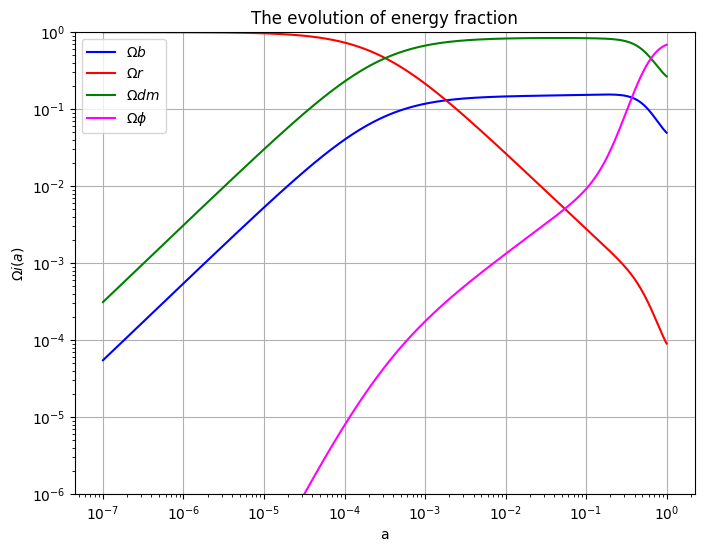

In [19]:
plt.figure(figsize=(8,6))
plt.plot(a,Omega_b, label = r'$\Omega b$', color = 'blue')
plt.plot(a,Omega_r,label = r'$\Omega r$', color = 'red')
plt.plot(a,Omega_dm,label = r'$\Omega dm$', color = 'green')
plt.plot(a,Omega_phi,label = r'$\Omega \phi$', color = 'magenta')
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-6,1)
plt.xlabel('a')
plt.ylabel(r"$\Omega i(a)$")
plt.legend()
plt.grid()
plt.title('The evolution of energy fraction')

In [ ]:
print(H_val.shape)
print(phiN.shape)
print(phi.shape)

(2000,)
(2000,)
(2000,)


In [20]:

P_phi = ((0.5 * H_val**2 * phiN**2) - V(phi,alpha,V0_best))
rho_phi = ((0.5 * H_val**2 * phiN**2) + V(phi,alpha,V0_best))

w_phi = P_phi / rho_phi
w_phi

array([-1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.        ,
        1.        ,  1.        ,  1.        ,  1.        ,  1.  

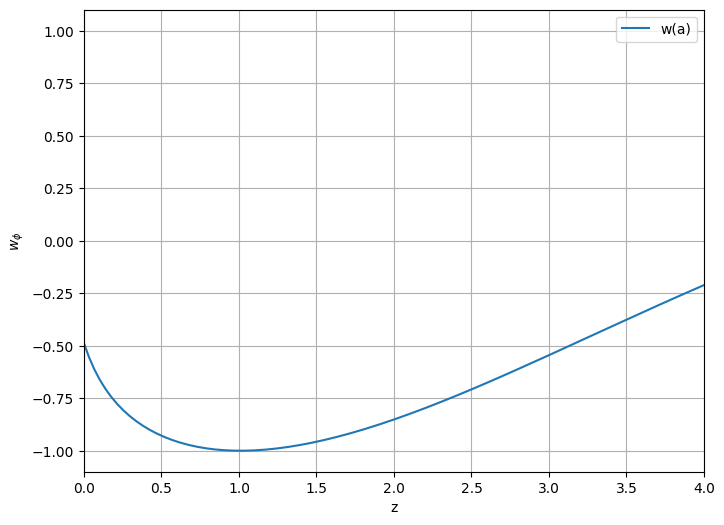

In [22]:
plt.figure(figsize=(8,6))

plt.plot((1/a) -1 ,w_phi,label= r'w(a)')


#plt.xscale('log')
plt.xlabel('z')
plt.ylabel(r'$w_{\phi}$')
plt.xlim(0,4)
plt.legend()
plt.grid()

In [23]:
x =  - (rho_dm_0 / (a**3 * rho_phi)) * ((f(phi,beta,gamma) / f0) - 1)


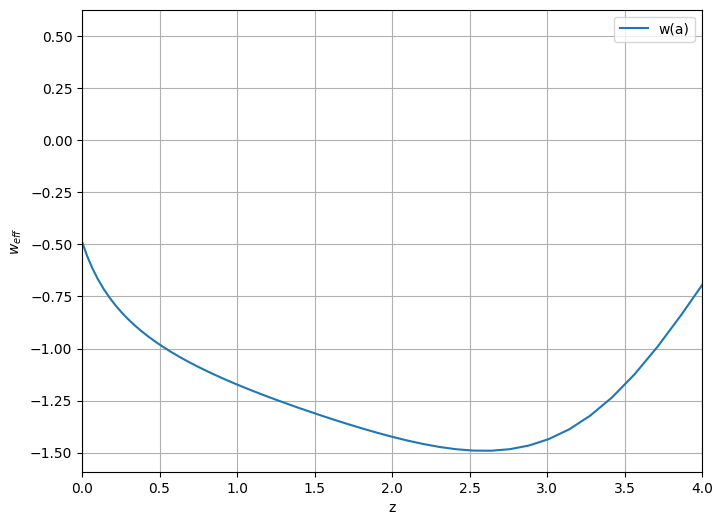

In [25]:
plt.figure(figsize=(8,6))

plt.plot((1/a) -1 ,w_phi / (1 - x),label= r'w(a)')


#plt.xscale('log')
plt.xlabel('z')
plt.ylabel(r'$w_{eff}$')
plt.xlim(0,4)
plt.legend()
plt.grid()